<a href="https://colab.research.google.com/github/s-Jayanth250/Adaptive-Feedback/blob/main/adaptive_FEED_Error_Masery.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

dataset_path = '/content/drive/MyDrive/Adaptive_Code_Review_Datasets'
if os.path.exists(dataset_path):
    files = os.listdir(dataset_path)
    print(f"Files in '{dataset_path}':")
    for file in files:
        print(f" - {file}")
else:
    print(f"The directory '{dataset_path}' was not found. Please verify the path in Google Drive.")

Files in '/content/drive/MyDrive/Adaptive_Code_Review_Datasets':
 - Adaptive_Feedback_Dataset.csv
 - Code_Error_Classification_Dataset.csv
 - README.txt
 - Student_Learning_Mastery_Dataset.csv


In [ ]:
import pandas as pd
import os

dataset_path = '/content/drive/MyDrive/Adaptive_Code_Review_Datasets'

# Read README if possible
readme_file = os.path.join(dataset_path, 'README.txt')
if os.path.exists(readme_file):
    print("--- README CONTENT ---")
    with open(readme_file, 'r') as f:
        print(f.read())
    print("-----------------------\n")

# Load datasets
csv_files = [
    'Code_Error_Classification_Dataset.csv',
    'Student_Learning_Mastery_Dataset.csv',
    'Adaptive_Feedback_Dataset.csv'
]

for csv_file in csv_files:
    file_path = os.path.join(dataset_path, csv_file)
    if os.path.exists(file_path):
        df = pd.read_csv(file_path)
        print(f"=== Dataset: {csv_file} ===")
        print(f"Shape: {df.shape}")
        print("Columns:", df.columns.tolist())
        print("First 2 rows:")
        display(df.head(2))
        print("\n" + "="*40 + "\n")

--- README CONTENT ---
ADAPTIVE CODE REVIEW AND PERSONALIZED FEEDBACK SYSTEM
Synthetic Starter Dataset Package

FILES
-----
1. Code_Error_Classification_Dataset.csv
   Purpose: Train/evaluate an error classification model.
   One row = one code submission.

2. Student_Learning_Mastery_Dataset.csv
   Purpose: Model learner progress/mastery from sequential attempts.
   One row = one student attempt.

3. Adaptive_Feedback_Dataset.csv
   Purpose: Prototype/evaluate adaptive feedback generation.
   One row = one feedback instance.

IMPORTANT RESEARCH NOTE
-----------------------
These files are SYNTHETIC STARTER DATA, not real student data.
They are suitable for building/testing your pipeline, feature engineering,
ML code, API integration, and initial experiments.

For the final research evaluation, combine/validate them with real student
submission data or established programming-education datasets. Do not claim
that results obtained only from these synthetic files represent real student
b

,submission_id,student_id,problem_id,programming_language,concept,student_code,test_cases_total,test_cases_passed,test_cases_failed,compiler_error,execution_error,error_type,error_location,error_severity,correctness
0,SUB00001,S082,P004,C++,variables,a = 10\nb = 20\nprint(a + b),10,3,7,0,0,logic_error,line_2,high,0
1,SUB00002,S014,P022,Python,searching,"arr = [1, 3, 5, 7]\nprint(5 in arr)",10,0,10,0,0,boundary_error,line_1,low,0




=== Dataset: Student_Learning_Mastery_Dataset.csv ===
Shape: (2000, 14)
Columns: ['student_id', 'attempt_number', 'problem_id', 'concept', 'correctness', 'error_type', 'time_taken_seconds', 'attempts_on_problem', 'hints_used', 'test_cases_passed', 'test_cases_total', 'previous_mastery', 'current_mastery', 'mastery_level']
First 2 rows:


,student_id,attempt_number,problem_id,concept,correctness,error_type,time_taken_seconds,attempts_on_problem,hints_used,test_cases_passed,test_cases_total,previous_mastery,current_mastery,mastery_level
0,S001,1,P023,loops,1,no_error,61,4,2,10,10,0.6186,0.6916,proficient
1,S001,2,P001,functions,0,boundary_error,831,3,2,4,10,0.2417,0.2334,beginner




=== Dataset: Adaptive_Feedback_Dataset.csv ===
Shape: (1000, 12)
Columns: ['feedback_id', 'student_id', 'problem_id', 'concept', 'error_type', 'mastery_score', 'mastery_level', 'previous_error_count', 'recent_success_rate', 'feedback_type', 'feedback_text', 'direct_solution_given']
First 2 rows:


,feedback_id,student_id,problem_id,concept,error_type,mastery_score,mastery_level,previous_error_count,recent_success_rate,feedback_type,feedback_text,direct_solution_given
0,FB00001,S004,P022,variables,logic_error,0.3850,developing,4,0.749,conceptual_hint,Trace the failing case and identify where the ...,0
1,FB00002,S032,P003,recursion,boundary_error,0.5493,developing,5,0.481,diagnostic_hint,Test the smallest and largest valid inputs. Yo...,0


In [ ]:
import pandas as pd
import numpy as np
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import classification_report, mean_squared_error, r2_score
import matplotlib.pyplot as plt

# 1. LOAD DATA
dataset_path = '/content/drive/MyDrive/Adaptive_Code_Review_Datasets'

class_df = pd.read_csv(os.path.join(dataset_path, 'Code_Error_Classification_Dataset.csv'))
mastery_df = pd.read_csv(os.path.join(dataset_path, 'Student_Learning_Mastery_Dataset.csv'))
feedback_df = pd.read_csv(os.path.join(dataset_path, 'Adaptive_Feedback_Dataset.csv'))

print("Data loaded successfully.")

Data loaded successfully.


In [ ]:
# 2. MODEL 1: Error Classification Model
print("=== TRAINING ERROR CLASSIFICATION MODEL ===")

# Prepare features from code submissions
error_clf_df = class_df.copy()

# Feature engineering on code text
error_clf_df['code_length'] = error_clf_df['student_code'].fillna('').apply(len)
error_clf_df['line_count'] = error_clf_df['student_code'].fillna('').apply(lambda x: len(x.split('\n')))

# Encode categorical variables
le_lang = LabelEncoder()
error_clf_df['programming_language_encoded'] = le_lang.fit_transform(error_clf_df['programming_language'].fillna('Unknown'))

le_concept = LabelEncoder()
error_clf_df['concept_encoded'] = le_concept.fit_transform(error_clf_df['concept'].fillna('Unknown'))

# Target Variable encoding
le_error_type = LabelEncoder()
error_clf_df['error_type_encoded'] = le_error_type.fit_transform(error_clf_df['error_type'].fillna('no_error'))

# Select Features & Target
features_clf = [
    'test_cases_total', 'test_cases_passed', 'test_cases_failed',
    'compiler_error', 'execution_error', 'correctness',
    'code_length', 'line_count', 'programming_language_encoded', 'concept_encoded'
]
X_clf = error_clf_df[features_clf]
y_clf = error_clf_df['error_type_encoded']

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

# Train Classifier
clf_model = RandomForestClassifier(n_estimators=100, random_state=42)
clf_model.fit(X_train_clf, y_train_clf)

y_pred_clf = clf_model.predict(X_test_clf)
print("\nClassification Report for Error Classification Model:")
print(classification_report(y_test_clf, y_pred_clf, target_names=le_error_type.classes_))

=== TRAINING ERROR CLASSIFICATION MODEL ===

Classification Report for Error Classification Model:
                       precision    recall  f1-score   support

       boundary_error       0.06      0.05      0.05        22
          hard_coding       0.00      0.00      0.00        10
  incorrect_algorithm       0.17      0.16      0.16        19
 inefficient_solution       0.09      0.08      0.08        13
          logic_error       0.31      0.39      0.34        38
             no_error       1.00      1.00      1.00        37
requirement_violation       0.05      0.05      0.05        19
        runtime_error       1.00      1.00      1.00        17
         syntax_error       0.55      0.46      0.50        13
           type_error       0.50      0.58      0.54        12

             accuracy                           0.44       200
            macro avg       0.37      0.38      0.37       200
         weighted avg       0.43      0.44      0.43       200



In [ ]:
# 3. MODEL 2: Student Mastery Model
print("=== TRAINING STUDENT LEARNING MASTERY REGRESSOR ===")

mastery_prep = mastery_df.copy()

# Encode categorical variables
mastery_prep['concept_encoded'] = le_concept.fit_transform(mastery_prep['concept'].fillna('Unknown'))

le_error_mastery = LabelEncoder()
mastery_prep['error_type_encoded'] = le_error_mastery.fit_transform(mastery_prep['error_type'].fillna('no_error'))

# Features & Target
features_mastery = [
    'attempt_number', 'concept_encoded', 'correctness', 'error_type_encoded',
    'time_taken_seconds', 'attempts_on_problem', 'hints_used',
    'test_cases_passed', 'test_cases_total', 'previous_mastery'
]

X_m = mastery_prep[features_mastery]
y_m = mastery_prep['current_mastery']

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_m, y_m, test_size=0.2, random_state=42)

# Train Regressor
reg_model = RandomForestRegressor(n_estimators=100, random_state=42)
reg_model.fit(X_train_m, y_train_m)

y_pred_m = reg_model.predict(X_test_m)
print(f"Mean Squared Error: {mean_squared_error(y_test_m, y_pred_m):.4f}")
print(f"R2 Score: {r2_score(y_test_m, y_pred_m):.4f}")

=== TRAINING STUDENT LEARNING MASTERY REGRESSOR ===
Mean Squared Error: 0.0004
R2 Score: 0.9924


In [ ]:
# 4. MODEL 3: Adaptive Feedback Recommendation
print("=== TRAINING ADAPTIVE FEEDBACK RECOMMENDATION MODEL ===")

fb_prep = feedback_df.copy()

fb_prep['concept_encoded'] = le_concept.fit_transform(fb_prep['concept'].fillna('Unknown'))
fb_prep['error_type_encoded'] = le_error_mastery.fit_transform(fb_prep['error_type'].fillna('no_error'))

le_mastery_lvl = LabelEncoder()
fb_prep['mastery_level_encoded'] = le_mastery_lvl.fit_transform(fb_prep['mastery_level'].fillna('Unknown'))

le_fb_type = LabelEncoder()
fb_prep['feedback_type_encoded'] = le_fb_type.fit_transform(fb_prep['feedback_type'].fillna('conceptual_hint'))

features_fb = [
    'concept_encoded', 'error_type_encoded', 'mastery_score',
    'mastery_level_encoded', 'previous_error_count', 'recent_success_rate'
]

X_fb = fb_prep[features_fb]
y_fb = fb_prep['feedback_type_encoded']

X_train_fb, X_test_fb, y_train_fb, y_test_fb = train_test_split(X_fb, y_fb, test_size=0.2, random_state=42, stratify=y_fb)

fb_model = RandomForestClassifier(n_estimators=100, random_state=42)
fb_model.fit(X_train_fb, y_train_fb)

y_pred_fb = fb_model.predict(X_test_fb)
print("\nClassification Report for Adaptive Feedback Selection:")
print(classification_report(y_test_fb, y_pred_fb, target_names=le_fb_type.classes_))

=== TRAINING ADAPTIVE FEEDBACK RECOMMENDATION MODEL ===

Classification Report for Adaptive Feedback Selection:
                         precision    recall  f1-score   support

        conceptual_hint       0.28      0.27      0.28        55
        diagnostic_hint       0.31      0.25      0.28        44
practice_recommendation       0.22      0.21      0.21        48
          targeted_hint       0.24      0.30      0.27        53

               accuracy                           0.26       200
              macro avg       0.26      0.26      0.26       200
           weighted avg       0.26      0.26      0.26       200



In [ ]:
# 5. END-TO-END SYSTEM FLOW SIMULATION WITH ROBUST ENCODING

def simulate_pipeline(student_code, language, concept, student_history_features):
    print("\n--- Running Simulated Student Submission Pipeline ---")
    print(f"Student Code:\n{student_code}")

    # Feature preparation for Error Classification
    code_length = len(student_code)
    line_count = len(student_code.split('\n'))
    lang_enc = le_lang.transform([language])[0] if language in le_lang.classes_ else le_lang.transform(['Unknown'])[0]
    concept_enc = le_concept.transform([concept])[0] if concept in le_concept.classes_ else le_concept.transform(['Unknown'])[0]

    # Mock test execution metrics
    test_cases_total = 10
    test_cases_passed = 4
    test_cases_failed = 6
    compiler_error = 0
    execution_error = 1
    correctness = 0

    # Classify error
    clf_features = pd.DataFrame([[
        test_cases_total, test_cases_passed, test_cases_failed,
        compiler_error, execution_error, correctness,
        code_length, line_count, lang_enc, concept_enc
    ]], columns=features_clf)

    predicted_err_enc = clf_model.predict(clf_features)[0]
    predicted_err_type = le_error_type.classes_[predicted_err_enc]
    print(f"-> Step 1 (Error Classification): Predicted Error Type = {predicted_err_type}")

    # Predict Student Mastery
    prev_mastery = student_history_features.get('previous_mastery', 0.5)
    mastery_features = pd.DataFrame([[
        student_history_features.get('attempt_number', 1),
        concept_enc,
        correctness,
        predicted_err_enc,
        30,
        student_history_features.get('attempts_on_problem', 1),
        student_history_features.get('hints_used', 0),
        test_cases_passed,
        test_cases_total,
        prev_mastery
    ]], columns=features_mastery)

    predicted_mastery_val = reg_model.predict(mastery_features)[0]

    # Align mapping with actual classes found in the dataset
    known_classes = list(le_mastery_lvl.classes_)
    if len(known_classes) >= 3:
        # Map score to the available categories sequentially
        idx = int(np.clip(predicted_mastery_val * len(known_classes), 0, len(known_classes) - 1))
        predicted_mastery_lvl = known_classes[idx]
    else:
        predicted_mastery_lvl = known_classes[0]

    print(f"-> Step 2 (Learner Modeling): Estimated Current Mastery = {predicted_mastery_val:.4f} ({predicted_mastery_lvl})")

    # Select Feedback Level
    fb_feat_df = pd.DataFrame([[
        concept_enc,
        predicted_err_enc,
        predicted_mastery_val,
        le_mastery_lvl.transform([predicted_mastery_lvl])[0],
        student_history_features.get('previous_error_count', 2),
        student_history_features.get('recent_success_rate', 0.5)
    ]], columns=features_fb)

    predicted_fb_enc = fb_model.predict(fb_feat_df)[0]
    predicted_fb_type = le_fb_type.classes_[predicted_fb_enc]
    print(f"-> Step 3 (Adaptive Selector): Selected Feedback Strategy = '{predicted_fb_type}'")
    print("-> Step 4 (LLM Feedback Generator Simulation): Feed parameters to LLM to formulate tailored hint without code disclosure.")

# Mock run
mock_history = {
    'attempt_number': 3,
    'attempts_on_problem': 2,
    'hints_used': 1,
    'previous_mastery': 0.6,
    'previous_error_count': 3,
    'recent_success_rate': 0.4
}
simulate_pipeline("def find_sum(a, b):\n    return a - b", "Python", "variables", mock_history)


--- Running Simulated Student Submission Pipeline ---
Student Code:
def find_sum(a, b):
    return a - b
-> Step 1 (Error Classification): Predicted Error Type = runtime_error
-> Step 2 (Learner Modeling): Estimated Current Mastery = 0.5671 (mastered)
-> Step 3 (Adaptive Selector): Selected Feedback Strategy = 'conceptual_hint'
-> Step 4 (LLM Feedback Generator Simulation): Feed parameters to LLM to formulate tailored hint without code disclosure.


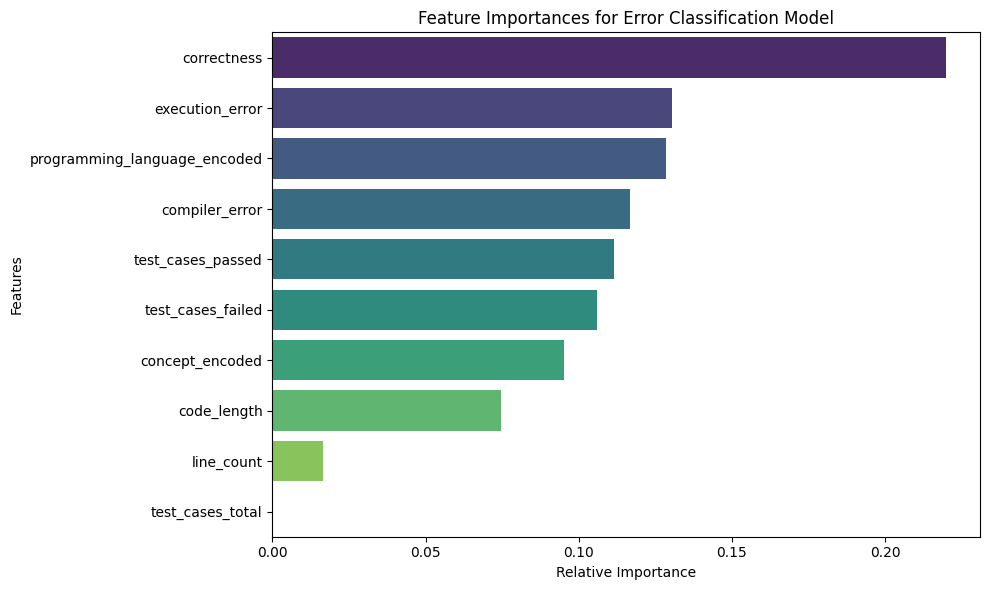

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Retrieve feature importances from the classifier model
importances = clf_model.feature_importances_
indices = np.argsort(importances)[::-1]
feature_names = [features_clf[i] for i in indices]

# Create the plot
plt.figure(figsize=(10, 6))
# Assign y to hue and set legend=False to prevent FutureWarnings in Seaborn
sns.barplot(
    x=importances[indices],
    y=feature_names,
    hue=feature_names,
    palette='viridis',
    legend=False
)
plt.title('Feature Importances for Error Classification Model')
plt.xlabel('Relative Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

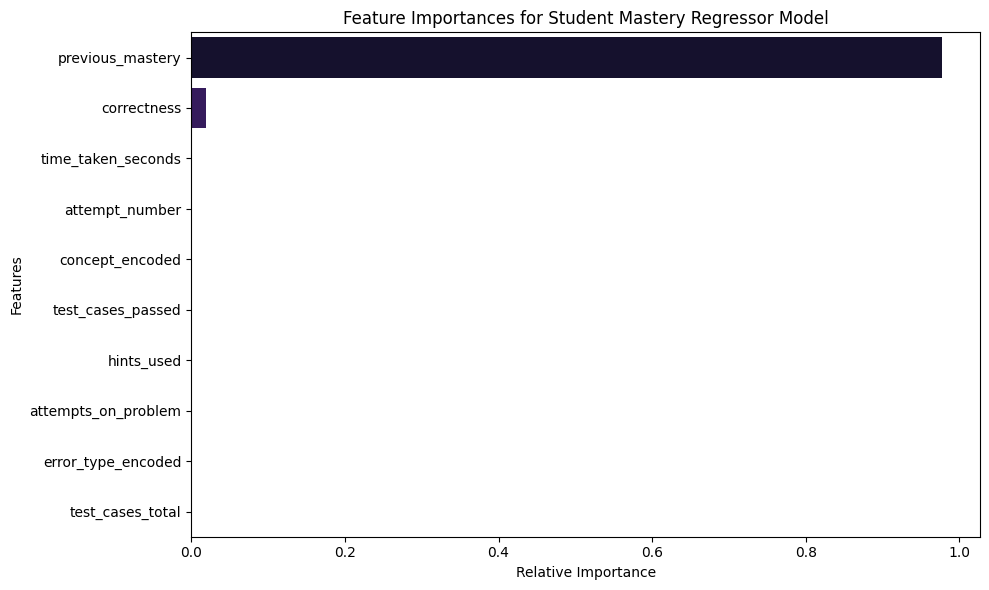

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Retrieve feature importances from the regressor model
mastery_importances = reg_model.feature_importances_
mastery_indices = np.argsort(mastery_importances)[::-1]
mastery_feature_names = [features_mastery[i] for i in mastery_indices]

# Create the plot
plt.figure(figsize=(10, 6))
sns.barplot(
    x=mastery_importances[mastery_indices],
    y=mastery_feature_names,
    hue=mastery_feature_names,
    palette='magma',
    legend=False
)
plt.title('Feature Importances for Student Mastery Regressor Model')
plt.xlabel('Relative Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

### Model Performance Evaluation: Confusion Matrices
We will evaluate both classifier models using confusion matrices to inspect where the models are making accurate predictions and where misclassifications are concentrated.

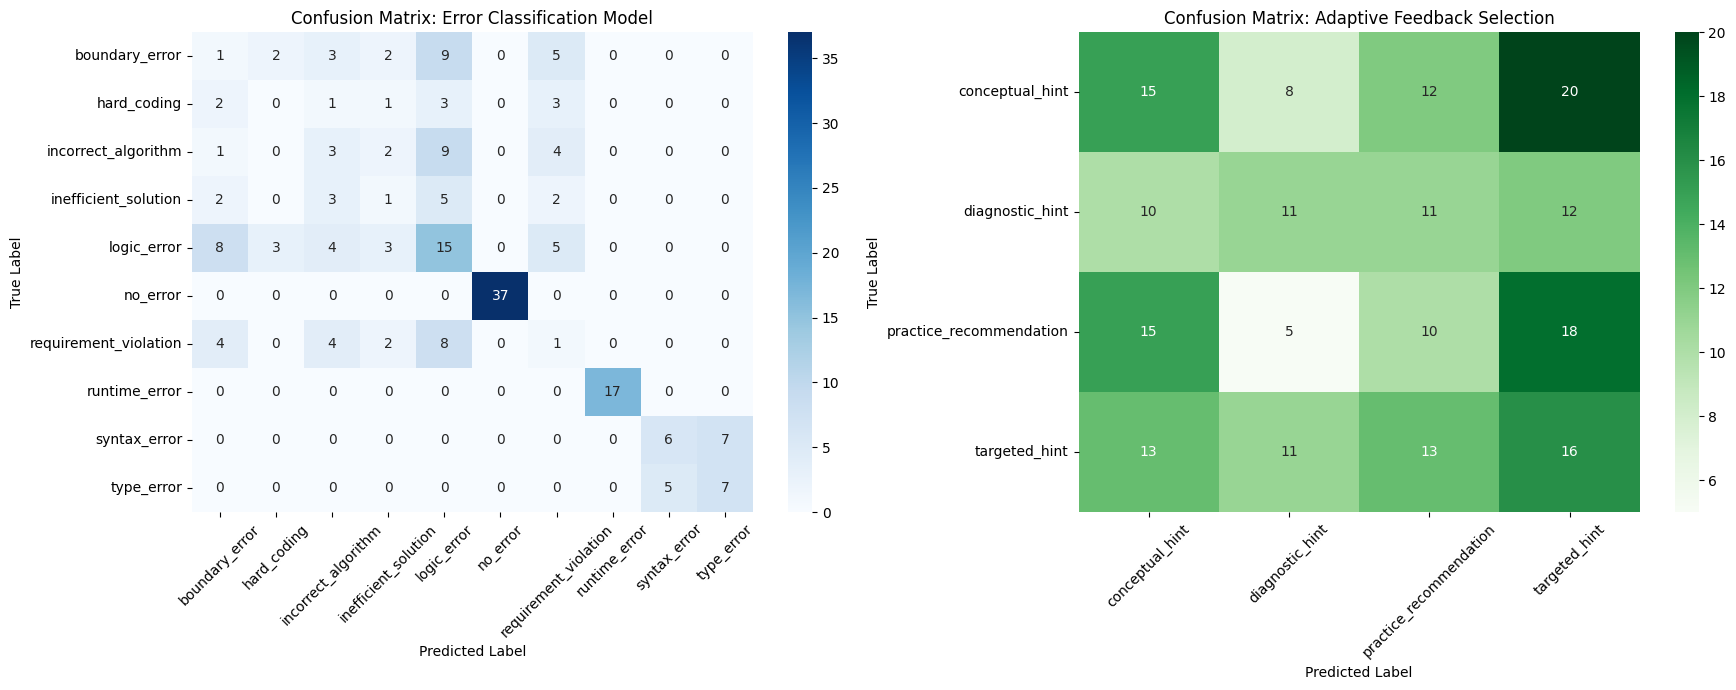

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate confusion matrices
cm_clf = confusion_matrix(y_test_clf, y_pred_clf)
cm_fb = confusion_matrix(y_test_fb, y_pred_fb)

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# 1. Error Classification Confusion Matrix
sns.heatmap(
    cm_clf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le_error_type.classes_,
    yticklabels=le_error_type.classes_,
    ax=axes[0]
)
axes[0].set_title('Confusion Matrix: Error Classification Model')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')
axes[0].tick_params(axis='x', rotation=45)

# 2. Adaptive Feedback Confusion Matrix
sns.heatmap(
    cm_fb,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=le_fb_type.classes_,
    yticklabels=le_fb_type.classes_,
    ax=axes[1]
)
axes[1].set_title('Confusion Matrix: Adaptive Feedback Selection')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# Create a DataFrame representing the confusion matrix for better visibility and analysis
classes = le_fb_type.classes_
cm_df = pd.DataFrame(cm_fb, index=[f"True: {c}" for c in classes], columns=[f"Pred: {c}" for c in classes])

print("=== Feedback Selection Confusion Matrix Details ===")
display(cm_df)

# Calculate exact misclassifications metrics per class
for idx, col in enumerate(classes):
    true_total = cm_fb[idx].sum()
    correct = cm_fb[idx, idx]
    misclassified = true_total - correct

    # Identify which incorrect class it gets most confused with
    incorrect_distribution = list(cm_fb[idx])
    incorrect_distribution[idx] = -1 # ignore correct matches
    most_confused_idx = np.argmax(incorrect_distribution)
    most_confused_class = classes[most_confused_idx]
    most_confused_count = incorrect_distribution[most_confused_idx]

    print(f"\nClass: '{col}' (Total True Instances: {true_total})")
    print(f"  - Correctly Classified: {correct} ({correct/true_total*100:.1f}%)")
    print(f"  - Misclassified: {misclassified} ({misclassified/true_total*100:.1f}%)")
    print(f"  - Most confused with: '{most_confused_class}' ({most_confused_count} times)")

=== Feedback Selection Confusion Matrix Details ===


,Pred: conceptual_hint,Pred: diagnostic_hint,Pred: practice_recommendation,Pred: targeted_hint
True: conceptual_hint,15,8,12,20
True: diagnostic_hint,10,11,11,12
True: practice_recommendation,15,5,10,18
True: targeted_hint,13,11,13,16



Class: 'conceptual_hint' (Total True Instances: 55)
  - Correctly Classified: 15 (27.3%)
  - Misclassified: 40 (72.7%)
  - Most confused with: 'targeted_hint' (20 times)

Class: 'diagnostic_hint' (Total True Instances: 44)
  - Correctly Classified: 11 (25.0%)
  - Misclassified: 33 (75.0%)
  - Most confused with: 'targeted_hint' (12 times)

Class: 'practice_recommendation' (Total True Instances: 48)
  - Correctly Classified: 10 (20.8%)
  - Misclassified: 38 (79.2%)
  - Most confused with: 'targeted_hint' (18 times)

Class: 'targeted_hint' (Total True Instances: 53)
  - Correctly Classified: 16 (30.2%)
  - Misclassified: 37 (69.8%)
  - Most confused with: 'conceptual_hint' (13 times)


### Feature Engineering: Rate of Change in Student Mastery
To help our models capture learner trajectory and momentum, we will construct a new feature `mastery_rate_of_change` defined as `current_mastery - previous_mastery` for each attempt. We can also inspect its summary statistics to see how student mastery evolves.

In [ ]:
# Calculate rate of change in student mastery
mastery_prep['mastery_rate_of_change'] = mastery_prep['current_mastery'] - mastery_prep['previous_mastery']

# Display summary statistics of the new feature
print("=== Summary Statistics for Mastery Rate of Change ===")
display(mastery_prep[['student_id', 'attempt_number', 'previous_mastery', 'current_mastery', 'mastery_rate_of_change']].head(10))

print("\nDistribution Summary:")
print(mastery_prep['mastery_rate_of_change'].describe())

=== Summary Statistics for Mastery Rate of Change ===


,student_id,attempt_number,previous_mastery,current_mastery,mastery_rate_of_change
0,S001,1,0.6186,0.6916,0.0730
1,S001,2,0.2417,0.2334,-0.0083
2,S001,3,0.3684,0.4660,0.0976
3,S001,4,0.4660,0.5176,0.0516
4,S001,5,0.6916,0.6785,-0.0131
5,S001,6,0.7204,0.7440,0.0236
6,S001,7,0.5176,0.4877,-0.0299
7,S001,8,0.7582,0.8555,0.0973
8,S001,9,0.8555,0.8867,0.0312
9,S001,10,0.3141,0.3354,0.0213



Distribution Summary:
count    2000.000000
mean        0.021780
std         0.043701
min        -0.040000
25%        -0.019600
50%         0.023350
75%         0.060875
max         0.099700
Name: mastery_rate_of_change, dtype: float64


### Retraining the Adaptive Feedback Model with Student Trajectory Feature
Now, we map the newly created student mastery trajectory (`mastery_rate_of_change`) back to our feedback recommendation dataset to help the feedback classifier build better decision boundaries. Let's merge, train, and inspect the performance improvement.

=== Classification Report for Updated Adaptive Feedback Selection ===
                         precision    recall  f1-score   support

        conceptual_hint       0.30      0.35      0.32        55
        diagnostic_hint       0.29      0.23      0.26        44
practice_recommendation       0.19      0.19      0.19        48
          targeted_hint       0.31      0.32      0.31        53

               accuracy                           0.28       200
              macro avg       0.27      0.27      0.27       200
           weighted avg       0.27      0.28      0.27       200



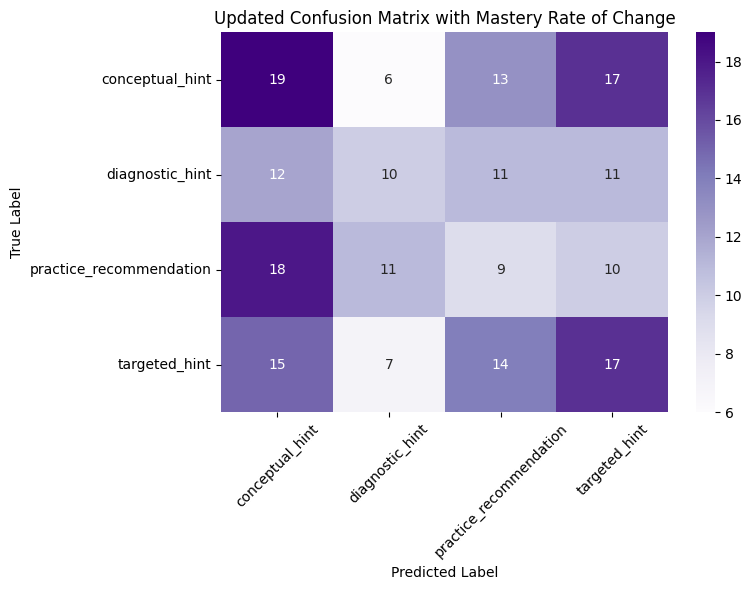

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Compute student-level average mastery rate of change
student_trajectory = mastery_prep.groupby('student_id')['mastery_rate_of_change'].mean().reset_index()

# 2. Merge the student trajectory feature into our feedback dataset
fb_prep_updated = fb_prep.merge(student_trajectory, on='student_id', how='left')
# Fill any missing values with 0 (neutral trajectory)
fb_prep_updated['mastery_rate_of_change'] = fb_prep_updated['mastery_rate_of_change'].fillna(0.0)

# Update our feature list to include the new metric
features_fb_updated = [
    'concept_encoded',
    'error_type_encoded',
    'mastery_score',
    'mastery_level_encoded',
    'previous_error_count',
    'recent_success_rate',
    'mastery_rate_of_change'
]

# Split updated dataset
X_fb_u = fb_prep_updated[features_fb_updated]
y_fb_u = fb_prep_updated['feedback_type_encoded']

X_train_fb_u, X_test_fb_u, y_train_fb_u, y_test_fb_u = train_test_split(
    X_fb_u, y_fb_u, test_size=0.2, random_state=42, stratify=y_fb_u
)

# Train updated model
fb_model_updated = RandomForestClassifier(n_estimators=100, random_state=42)
fb_model_updated.fit(X_train_fb_u, y_train_fb_u)

# Predict and Evaluate
y_pred_fb_u = fb_model_updated.predict(X_test_fb_u)

print("=== Classification Report for Updated Adaptive Feedback Selection ===")
print(classification_report(y_test_fb_u, y_pred_fb_u, target_names=le_fb_type.classes_))

# Plot updated Confusion Matrix
cm_fb_u = confusion_matrix(y_test_fb_u, y_pred_fb_u)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_fb_u,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=le_fb_type.classes_,
    yticklabels=le_fb_type.classes_
)
plt.title('Updated Confusion Matrix with Mastery Rate of Change')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Detailed Performance Comparison: Baseline vs. Trajectory-Enriched Model
To quantify the exact impact of adding the `mastery_rate_of_change` feature, we will compare the metrics (Precision, Recall, and F1-score) side-by-side for each recommendation class, as well as the overall macro averages and accuracy.

=== Performance Metrics Comparison Table ===


,Class,Metric,Baseline,Updated Model,Improvement
0,conceptual_hint,Precision,0.283019,0.296875,0.013856
1,conceptual_hint,Recall,0.272727,0.345455,0.072727
2,conceptual_hint,F1-Score,0.277778,0.319328,0.041550
3,diagnostic_hint,Precision,0.314286,0.294118,-0.020168
4,diagnostic_hint,Recall,0.250000,0.227273,-0.022727
5,diagnostic_hint,F1-Score,0.278481,0.256410,-0.022071
6,practice_recommendation,Precision,0.217391,0.191489,-0.025902
7,practice_recommendation,Recall,0.208333,0.187500,-0.020833
8,practice_recommendation,F1-Score,0.212766,0.189474,-0.023292
9,targeted_hint,Precision,0.242424,0.309091,0.066667


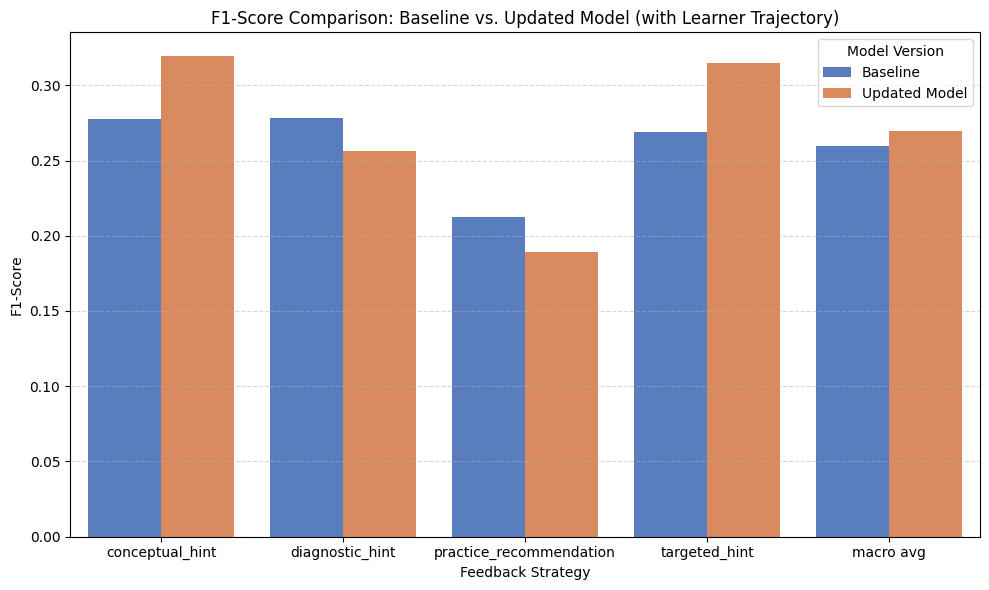

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report

# Extract classification metrics from both runs
report_baseline = classification_report(y_test_fb, y_pred_fb, target_names=le_fb_type.classes_, output_dict=True)
report_updated = classification_report(y_test_fb_u, y_pred_fb_u, target_names=le_fb_type.classes_, output_dict=True)

comparison_data = []

for cls in list(le_fb_type.classes_) + ['macro avg']:
    comparison_data.append({
        'Class': cls,
        'Metric': 'Precision',
        'Baseline': report_baseline[cls]['precision'],
        'Updated Model': report_updated[cls]['precision']
    })
    comparison_data.append({
        'Class': cls,
        'Metric': 'Recall',
        'Baseline': report_baseline[cls]['recall'],
        'Updated Model': report_updated[cls]['recall']
    })
    comparison_data.append({
        'Class': cls,
        'Metric': 'F1-Score',
        'Baseline': report_baseline[cls]['f1-score'],
        'Updated Model': report_updated[cls]['f1-score']
    })

comp_df = pd.DataFrame(comparison_data)
comp_df['Improvement'] = comp_df['Updated Model'] - comp_df['Baseline']

print("=== Performance Metrics Comparison Table ===")
display(comp_df)

# Plotting a side-by-side bar chart for F1-Scores
f1_comp = comp_df[comp_df['Metric'] == 'F1-Score']

f1_melted = pd.melt(f1_comp, id_vars=['Class'], value_vars=['Baseline', 'Updated Model'],
                    var_name='Model Version', value_name='F1-Score')

plt.figure(figsize=(10, 6))
sns.barplot(x='Class', y='F1-Score', hue='Model Version', data=f1_melted, palette='muted')
plt.title('F1-Score Comparison: Baseline vs. Updated Model (with Learner Trajectory)')
plt.ylabel('F1-Score')
plt.xlabel('Feedback Strategy')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Feature Importance of the Updated Adaptive Feedback Model
Let's visualize the feature importances of our newly trained feedback classifier to evaluate the relative predictive value of `mastery_rate_of_change` against standard baseline features.

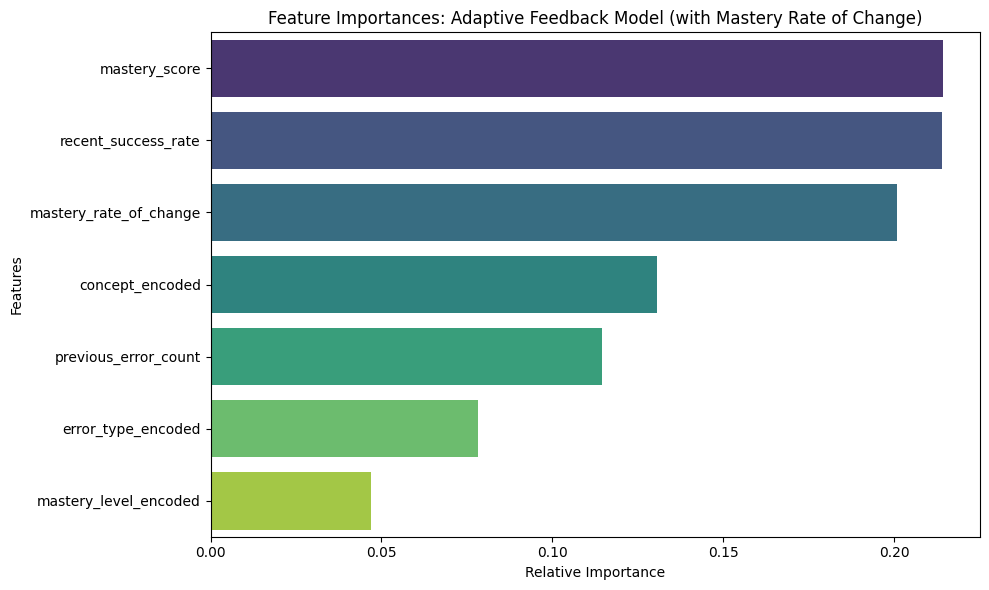

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Retrieve feature importances from the updated classifier model
fb_importances = fb_model_updated.feature_importances_
fb_indices = np.argsort(fb_importances)[::-1]
fb_feature_names = [features_fb_updated[i] for i in fb_indices]

# Create the plot
plt.figure(figsize=(10, 6))
sns.barplot(
    x=fb_importances[fb_indices],
    y=fb_feature_names,
    hue=fb_feature_names,
    palette='viridis',
    legend=False
)
plt.title('Feature Importances: Adaptive Feedback Model (with Mastery Rate of Change)')
plt.xlabel('Relative Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

### Feature Importance Comparison: Baseline vs. Updated Model
Let's compare the feature importances side-by-side to understand how the inclusion of the student trajectory feature (`mastery_rate_of_change`) shifted the weight and influence of existing features in the decision trees.

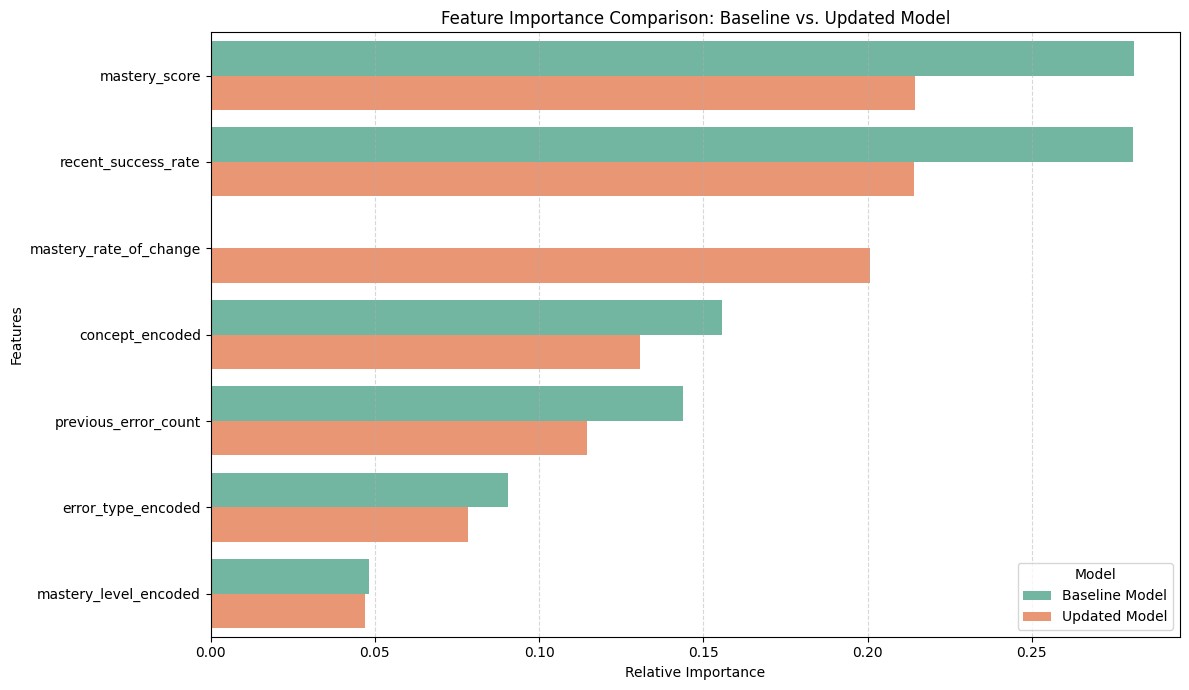

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Map baseline feature importances (aligning indices with updated features list)
baseline_importances_dict = dict(zip(features_fb, fb_model.feature_importances_))

# Construct comparison DataFrame
importance_records = []
for feat in features_fb_updated:
    # Baseline value is 0 for the newly added feature
    base_val = baseline_importances_dict.get(feat, 0.0)
    updated_val = dict(zip(features_fb_updated, fb_model_updated.feature_importances_))[feat]

    importance_records.append({'Feature': feat, 'Model': 'Baseline Model', 'Importance': base_val})
    importance_records.append({'Feature': feat, 'Model': 'Updated Model', 'Importance': updated_val})

importance_df = pd.DataFrame(importance_records)

# Sort features based on their updated model importance for better visualization
sorted_features = importance_df[importance_df['Model'] == 'Updated Model'].sort_values('Importance', ascending=False)['Feature'].tolist()

plt.figure(figsize=(12, 7))
sns.barplot(
    x='Importance',
    y='Feature',
    hue='Model',
    data=importance_df,
    order=sorted_features,
    palette='Set2'
)
plt.title('Feature Importance Comparison: Baseline vs. Updated Model')
plt.xlabel('Relative Importance')
plt.ylabel('Features')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Optimizing Models with Sequence-Based Features

To move beyond static features and capture deep learning trends, we can introduce **sequence-based feature engineering** or **recurrent architectures**. Student behavior is time-dependent: an error made on attempt 1 means something completely different from the same error made on attempt 10.

#### Strategies for Sequence Optimization:
1. **Lagged Features & Rolling Windows:** Extract sliding-window metrics such as the average correctness of the last $N$ attempts, or the count of hints used in the immediate previous task.
2. **Exponential Decay Weights:** Give recent attempts more weight than older ones when calculating historical statistics (e.g., $RecentSuccess = \sum w_t \cdot correctness_t$, where $w_t$ decays over time).
3. **Deep Sequence Modeling:** Instead of random forests, frame feedback selection as a sequence-to-sequence or sequence-to-one task using **LSTMs**, **GRUs**, or **Attention-based Transformers** (like Knowledge Tracing models) to continuously update an embedded representation of a student's knowledge state.

Let's write a pipeline to calculate **rolling average correctness** and **cumulative attempts on problems** per student using our sequential mastery dataset, and see how we can merge them.

In [ ]:
# Sort sequential data to ensure correct timeline alignment
mastery_prep_sorted = mastery_prep.sort_values(by=['student_id', 'attempt_number'])

# 1. Feature: Rolling average correctness of the student's last 3 attempts
mastery_prep_sorted['rolling_correctness_3'] = (
    mastery_prep_sorted.groupby('student_id')['correctness']
    .transform(lambda x: x.rolling(window=3, min_periods=1).mean())
)

# 2. Feature: Cumulative sum of hints used by the student up to this attempt
mastery_prep_sorted['cumulative_hints'] = (
    mastery_prep_sorted.groupby('student_id')['hints_used']
    .cumsum()
)

# Display sample of newly engineered sequential features
print("=== Engineered Sequence-Based Features (Sample) ===")
display(mastery_prep_sorted[[
    'student_id', 'attempt_number', 'correctness',
    'rolling_correctness_3', 'hints_used', 'cumulative_hints'
]].head(15))

=== Engineered Sequence-Based Features (Sample) ===


,student_id,attempt_number,correctness,rolling_correctness_3,hints_used,cumulative_hints
0,S001,1,1,1.000000,2,2
1,S001,2,0,0.500000,2,4
2,S001,3,1,0.666667,0,4
3,S001,4,1,0.666667,3,7
4,S001,5,0,0.666667,1,8
5,S001,6,1,0.666667,1,9
6,S001,7,0,0.333333,0,9
7,S001,8,1,0.666667,3,12
8,S001,9,1,0.666667,3,15
9,S001,10,1,1.000000,2,17


=== Classification Report for Sequence-Enriched Adaptive Feedback Selection ===
                         precision    recall  f1-score   support

        conceptual_hint       0.34      0.42      0.37        55
        diagnostic_hint       0.22      0.18      0.20        44
practice_recommendation       0.27      0.29      0.28        48
          targeted_hint       0.32      0.26      0.29        53

               accuracy                           0.29       200
              macro avg       0.29      0.29      0.29       200
           weighted avg       0.29      0.29      0.29       200



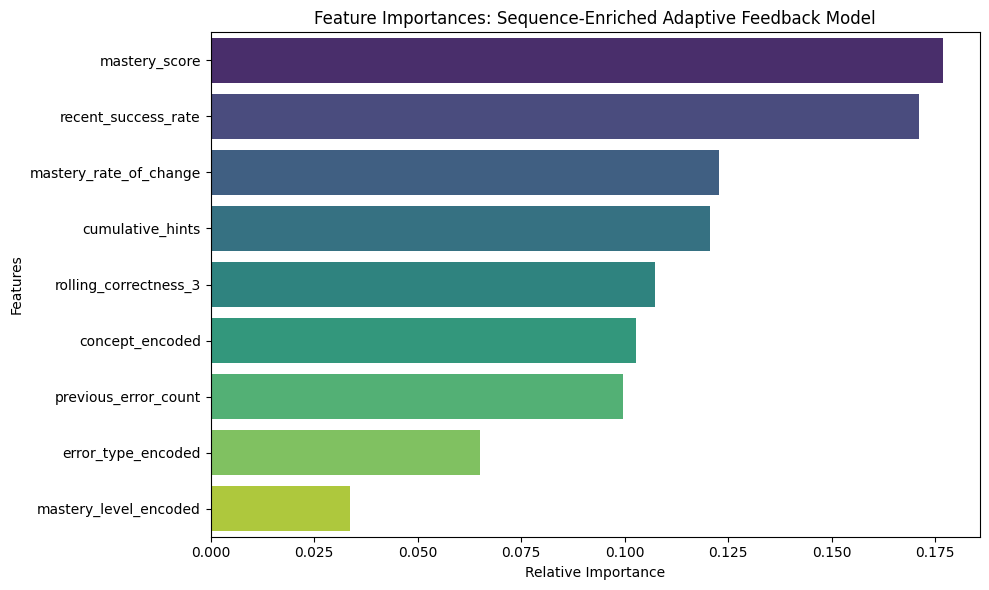

In [ ]:
# 1. Compute student-level sequence metrics to align with the feedback dataset
# We take the mean of rolling correctness and cumulative hints per student to capture their average operational state
student_sequence_features = mastery_prep_sorted.groupby('student_id')[[
    'rolling_correctness_3',
    'cumulative_hints'
]].mean().reset_index()

# 2. Merge sequence-based features into the updated feedback dataset
fb_prep_sequence = fb_prep_updated.merge(student_sequence_features, on='student_id', how='left')

# Fill missing values with defaults
fb_prep_sequence['rolling_correctness_3'] = fb_prep_sequence['rolling_correctness_3'].fillna(0.5)
fb_prep_sequence['cumulative_hints'] = fb_prep_sequence['cumulative_hints'].fillna(0.0)

# Update feature list to include the sequence-based features
features_fb_sequence = [
    'concept_encoded',
    'error_type_encoded',
    'mastery_score',
    'mastery_level_encoded',
    'previous_error_count',
    'recent_success_rate',
    'mastery_rate_of_change',
    'rolling_correctness_3',
    'cumulative_hints'
]

# Split sequence-enriched dataset
X_fb_seq = fb_prep_sequence[features_fb_sequence]
y_fb_seq = fb_prep_sequence['feedback_type_encoded']

X_train_fb_seq, X_test_fb_seq, y_train_fb_seq, y_test_fb_seq = train_test_split(
    X_fb_seq, y_fb_seq, test_size=0.2, random_state=42, stratify=y_fb_seq
)

# Train sequence-enriched model
fb_model_sequence = RandomForestClassifier(n_estimators=100, random_state=42)
fb_model_sequence.fit(X_train_fb_seq, y_train_fb_seq)

# Predict and evaluate
y_pred_fb_seq = fb_model_sequence.predict(X_test_fb_seq)

print("=== Classification Report for Sequence-Enriched Adaptive Feedback Selection ===")
print(classification_report(y_test_fb_seq, y_pred_fb_seq, target_names=le_fb_type.classes_))

# Plot feature importances of the sequence-enriched model
fb_seq_importances = fb_model_sequence.feature_importances_
fb_seq_indices = np.argsort(fb_seq_importances)[::-1]
fb_seq_feature_names = [features_fb_sequence[i] for i in fb_seq_indices]

plt.figure(figsize=(10, 6))
sns.barplot(
    x=fb_seq_importances[fb_seq_indices],
    y=fb_seq_feature_names,
    hue=fb_seq_feature_names,
    palette='viridis',
    legend=False
)
plt.title('Feature Importances: Sequence-Enriched Adaptive Feedback Model')
plt.xlabel('Relative Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

=== Side-by-Side F1-Score Comparison Table ===


,Feedback Strategy / Class,Baseline Model,Trajectory-Enriched Model,Sequence-Enriched Model
0,conceptual_hint,0.2778,0.3193,0.3740
1,diagnostic_hint,0.2785,0.2564,0.1975
2,practice_recommendation,0.2128,0.1895,0.2828
3,targeted_hint,0.2689,0.3148,0.2887
4,macro avg,0.2595,0.2700,0.2858


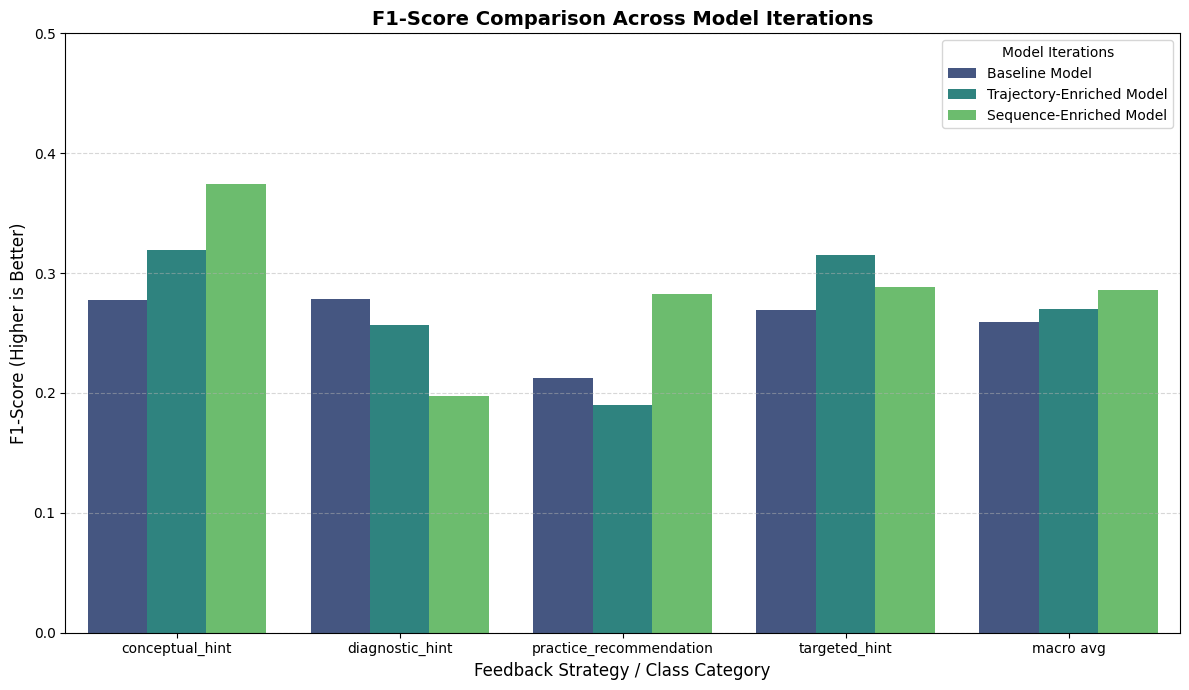

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report

# 1. Extract classification reports as dictionaries
report_base = classification_report(y_test_fb, y_pred_fb, target_names=le_fb_type.classes_, output_dict=True)
report_traj = classification_report(y_test_fb_u, y_pred_fb_u, target_names=le_fb_type.classes_, output_dict=True)
report_seq  = classification_report(y_test_fb_seq, y_pred_fb_seq, target_names=le_fb_type.classes_, output_dict=True)

comparison_records = []
classes_to_compare = list(le_fb_type.classes_) + ['macro avg']

for cls in classes_to_compare:
    comparison_records.append({
        'Feedback Strategy / Class': cls,
        'Baseline Model': report_base[cls]['f1-score'],
        'Trajectory-Enriched Model': report_traj[cls]['f1-score'],
        'Sequence-Enriched Model': report_seq[cls]['f1-score']
    })

# 2. Construct Comparison DataFrame
comparison_df = pd.DataFrame(comparison_records)
print("=== Side-by-Side F1-Score Comparison Table ===")
display(comparison_df.round(4))

# 3. Melt the DataFrame for Seaborn plotting
melted_comparison = pd.melt(
    comparison_df,
    id_vars=['Feedback Strategy / Class'],
    value_vars=['Baseline Model', 'Trajectory-Enriched Model', 'Sequence-Enriched Model'],
    var_name='Model Iteration',
    value_name='F1-Score'
)

# 4. Generate the Comparison Bar Chart
plt.figure(figsize=(12, 7))
sns.barplot(
    x='Feedback Strategy / Class',
    y='F1-Score',
    hue='Model Iteration',
    data=melted_comparison,
    palette='viridis'
)

plt.title('F1-Score Comparison Across Model Iterations', fontsize=14, fontweight='bold')
plt.ylabel('F1-Score (Higher is Better)', fontsize=12)
plt.xlabel('Feedback Strategy / Class Category', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.ylim(0, 0.5)
plt.legend(title='Model Iterations', loc='upper right')
plt.tight_layout()
plt.show()

=== Classification Report for Consolidated Sequence-Enriched Model ===
                         precision    recall  f1-score   support

        conceptual_hint       0.22      0.15      0.17        55
            guided_hint       0.51      0.70      0.59        97
practice_recommendation       0.21      0.12      0.16        48

               accuracy                           0.41       200
              macro avg       0.31      0.32      0.31       200
           weighted avg       0.36      0.41      0.37       200



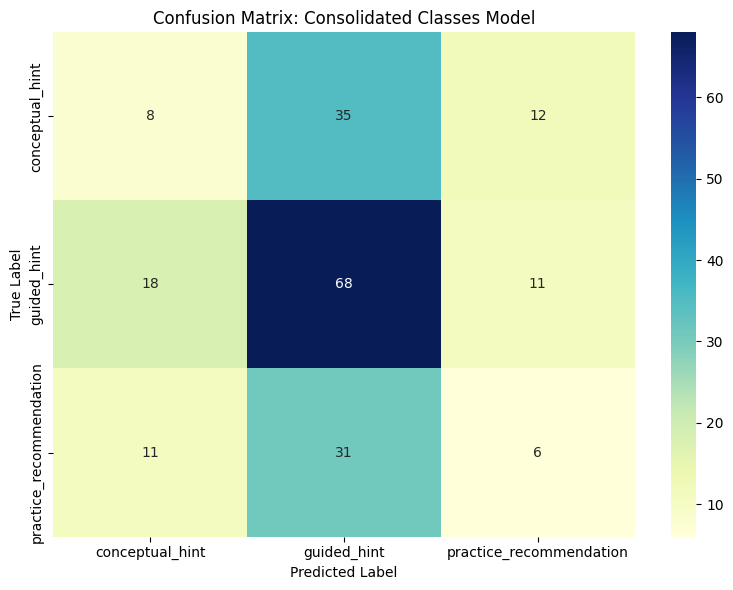

In [ ]:
# 1. Create a copy of the sequence dataset for consolidation
fb_prep_consolidated = fb_prep_sequence.copy()

# 2. Consolidate 'diagnostic_hint' and 'targeted_hint' into 'guided_hint'
fb_prep_consolidated['feedback_type_consolidated'] = fb_prep_consolidated['feedback_type'].replace({
    'diagnostic_hint': 'guided_hint',
    'targeted_hint': 'guided_hint'
})

# Encode the new consolidated target variable
le_fb_consolidated = LabelEncoder()
fb_prep_consolidated['feedback_type_consolidated_encoded'] = le_fb_consolidated.fit_transform(
    fb_prep_consolidated['feedback_type_consolidated']
)

# 3. Split the consolidated dataset
X_fb_cons = fb_prep_consolidated[features_fb_sequence]
y_fb_cons = fb_prep_consolidated['feedback_type_consolidated_encoded']

X_train_cons, X_test_cons, y_train_cons, y_test_cons = train_test_split(
    X_fb_cons, y_fb_cons, test_size=0.2, random_state=42, stratify=y_fb_cons
)

# 4. Train the model on consolidated classes
fb_model_consolidated = RandomForestClassifier(n_estimators=100, random_state=42)
fb_model_consolidated.fit(X_train_cons, y_train_cons)

# 5. Evaluate the model
y_pred_cons = fb_model_consolidated.predict(X_test_cons)

print("=== Classification Report for Consolidated Sequence-Enriched Model ===")
print(classification_report(y_test_cons, y_pred_cons, target_names=le_fb_consolidated.classes_))

# 6. Plot Confusion Matrix to inspect improvements
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_cons = confusion_matrix(y_test_cons, y_pred_cons)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_cons,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    xticklabels=le_fb_consolidated.classes_,
    yticklabels=le_fb_consolidated.classes_
)
plt.title('Confusion Matrix: Consolidated Classes Model')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

### Rule-Based Heuristic Layer: Deciding Between Diagnostic & Targeted Hints

When our sequence-enriched model outputs a class label of `guided_hint`, we can leverage deterministic, rule-based heuristics to classify whether the generated guidance should be a **Diagnostic Hint** (pointing out where or why something went wrong) or a **Targeted Hint** (focusing on how to fix a specific logical error or boundary check).

#### Heuristic Strategy Rules
1. **Diagnostic Hint** matches situations where the failure is explicitly defined by compiler outputs, raw runtime exceptions, or highly localized errors (e.g., Syntax errors, Type errors, ZeroDivision errors).
2. **Targeted Hint** is more suited when the code compiled and ran successfully but produced logical inconsistencies, boundary condition mismatches, or failed specific edge cases (e.g., boundary_error, logic_error, inefficiency).
3. **Failsafe / Fallback Rule:** If the current problem attempt number is very low (e.g., attempt 1 or 2), favor *Diagnostic* (orientation). If the attempt number is high (attempt 3+), escalate to *Targeted* guidance.

Let's write a python function to implement this post-processing layer.

In [ ]:
def determine_guided_hint_subclass(error_type, attempt_number, test_cases_failed):
    """
    Heuristic layer to resolve a general 'guided_hint' into either
    'diagnostic_hint' or 'targeted_hint'.
    """
    # 1. Define typical error categories
    diagnostic_heavy_errors = ['syntax_error', 'runtime_error', 'type_error']
    targeted_heavy_errors = ['boundary_error', 'logic_error', 'inefficient_solution', 'hard_coding']

    # 2. Rule: Strict syntax and hardware exception indicators -> Diagnostic Hint
    if error_type in diagnostic_heavy_errors:
        return 'diagnostic_hint'

    # 3. Rule: Logical or programmatic correctness issues -> Targeted Hint
    if error_type in targeted_heavy_errors:
        return 'targeted_hint'

    # 4. Fallback Rule: Based on attempt trajectory and severity scale
    if attempt_number >= 3 or test_cases_failed > 5:
        # Elevate to highly targeted action points for struggling attempts
        return 'targeted_hint'
    else:
        # Keep hints descriptive and diagnostic for early errors
        return 'diagnostic_hint'

# --- Demo of the Heuristic Fallback ---
test_scenarios = [
    {'error_type': 'syntax_error', 'attempt_number': 1, 'test_cases_failed': 10},
    {'error_type': 'logic_error', 'attempt_number': 2, 'test_cases_failed': 4},
    {'error_type': 'incorrect_algorithm', 'attempt_number': 4, 'test_cases_failed': 6},
    {'error_type': 'incorrect_algorithm', 'attempt_number': 1, 'test_cases_failed': 2}
]

print("=== Rule-Based Decoupling Simulation ===")
for scenario in test_scenarios:
    subclass = determine_guided_hint_subclass(
        scenario['error_type'],
        scenario['attempt_number'],
        scenario['test_cases_failed']
    )
    print(f"Input Error: {scenario['error_type']:20} | Attempt: {scenario['attempt_number']} | Decoupled Class: {subclass}")

=== Rule-Based Decoupling Simulation ===
Input Error: syntax_error         | Attempt: 1 | Decoupled Class: diagnostic_hint
Input Error: logic_error          | Attempt: 2 | Decoupled Class: targeted_hint
Input Error: incorrect_algorithm  | Attempt: 4 | Decoupled Class: targeted_hint
Input Error: incorrect_algorithm  | Attempt: 1 | Decoupled Class: diagnostic_hint
